## Principle Component Analysis (PCA)

In [19]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# We have 3 features PCA will reduce them to 2 features (PC1 and PC2) while preserving maximum information (variance).

np.set_printoptions(suppress=True)


# STEP 1 : CREATE SAMPLE DATA
np.random.seed(23)

# Class 1 centered around (0,0,0)
mu_vec1 = np.array([0,0,0])
cov_mat1 = np.array([
    [1,0,0],
    [0,1,0],
    [0,0,1]
])

class1_sample = np.random.multivariate_normal(mu_vec1, cov_mat1, 20)
df = pd.DataFrame(class1_sample, columns=['feature1','feature2','feature3'])
df['target'] = 1


# Class 2 centered around (1,1,1)
mu_vec2 = np.array([1,1,1])
cov_mat2 = np.array([
    [1,0,0],
    [0,1,0],
    [0,0,1]
])

class2_sample = np.random.multivariate_normal(mu_vec2, cov_mat2, 20)

df2 = pd.DataFrame(class2_sample, columns=['feature1','feature2','feature3'])
df2['target'] = 0

# Combine both classes
df = pd.concat([df,df2],ignore_index=True)
# Shuffle rows
df = df.sample(frac=1,random_state=42)

print("ORIGINAL DATA")

print(df.head())

print("\nShape :",df.shape)

# STEP 2 : STANDARDIZATION

# PCA is variance based. Features with large values dominate PCA.
# mean = 0 and std  = 1 for every feature using scalar

scaler = StandardScaler()

df.iloc[:,0:3] = scaler.fit_transform(df.iloc[:,0:3])


print("AFTER STANDARDIZATION")
print(df.head())

print("\nMeans")
print(df.iloc[:,0:3].mean())

print("\nStandard Deviations")
print(df.iloc[:,0:3].std())

# STEP 3 : COVARIANCE MATRIX
# Covariance tells us how features move together.

# Positive covariance: Feature A increases -> Feature B increases
# Negative covariance:Feature A increases -> Feature B decreases

covariance_matrix = np.cov([
    df.iloc[:,0],
    df.iloc[:,1],
    df.iloc[:,2]
])

print("COVARIANCE MATRIX")
print(covariance_matrix)


# STEP 4 : EIGEN VALUES AND EIGEN VECTORS

# Eigenvector  -> Direction
# Eigenvalue   -> Importance of that direction
# PCA keeps directions having largest eigenvalues.

eigen_values,eigen_vectors = np.linalg.eig(covariance_matrix)

print("EIGEN VALUES")
print(eigen_values)


print("EIGEN VECTORS")
print(eigen_vectors)


# STEP 5 : VARIANCE EXPLAINED

total_variance = np.sum(eigen_values)
print("VARIANCE EXPLAINED")


for i,val in enumerate(eigen_values):
    ratio = val/total_variance
    print(
        f"PC{i+1} explains "
        f"{ratio*100:.2f}% variance"
    )

# STEP 6 : SORT PCs
# Largest eigenvalue = Most important PC

sorted_index = np.argsort(eigen_values)[::-1]
eigen_values = eigen_values[sorted_index]
eigen_vectors = eigen_vectors[:,sorted_index]


print("SORTED EIGEN VALUES")
print(eigen_values)

print("SORTED EIGEN VECTORS")
print(eigen_vectors)


# STEP 7 : CHOOSE TOP 2 PCs
# Original dimensions = 3
# Keep only first 2 PCs
# New dimensions = 2

pc = eigen_vectors[:,0:2]

print("SELECTED PRINCIPAL COMPONENTS")
print(pc)


# STEP 8 : PROJECT DATA

# Original Shape: (40,3)
# Principal Components: (3,2)
# Dot Product: (40,3) x (3,2)
# Result: (40,2)
# This is dimensionality reduction.

transformed_data = np.dot(
    df.iloc[:,0:3],
    pc
)

print("TRANSFORMED DATA")
print(transformed_data[:5])

print("\nShape After PCA")
print(transformed_data.shape)

# ==========================================================
# STEP 9 : CREATE NEW DATAFRAME
# ==========================================================

new_df = pd.DataFrame(
    transformed_data,
    columns=['PC1','PC2']
)

new_df['target'] = df['target'].values


print("FINAL PCA DATAFRAME")

print(new_df.head())

# ==========================================================
# STEP 10 : VERIFY INFORMATION RETAINED
# ==========================================================

variance_retained = (
    np.sum(eigen_values[:2])
    /
    np.sum(eigen_values)
)

print("INFORMATION RETAINED")

print(
    f"Variance retained = "
    f"{variance_retained*100:.2f}%"
)

# ==========================================================
# INTERPRETATION
# ==========================================================
#
# Before PCA:
# feature1
# feature2
# feature3
#
# shape = (40,3)
#
#
# After PCA:
#
# PC1
# PC2
#
# shape = (40,2)
#
#
# PC1 = direction with maximum variance
#
# PC2 = second best direction
#
# PC3 discarded
#
# We compressed 3 dimensions into 2 dimensions
# while preserving most of the information.

ORIGINAL DATA
    feature1  feature2  feature3  target
19 -0.992574 -0.161346  1.192404       1
16 -0.420844 -0.551989 -0.121098       1
15 -0.045438  1.040886 -0.094035       1
26  0.898907  0.435960  0.820964       0
4   0.322272  0.060343 -1.043450       1

Shape : (40, 4)
AFTER STANDARDIZATION
    feature1  feature2  feature3  target
19 -1.247471 -0.593851  0.461269       1
16 -0.747423 -0.966733 -0.693369       1
15 -0.419084  0.553723 -0.669580       1
26  0.406862 -0.023700  0.134754       0
4  -0.097477 -0.382241 -1.504166       1

Means
feature1   -6.383782e-17
feature2    2.775558e-17
feature3   -2.220446e-17
dtype: float64

Standard Deviations
feature1    1.012739
feature2    1.012739
feature3    1.012739
dtype: float64
COVARIANCE MATRIX
[[1.02564103 0.20478114 0.080118  ]
 [0.20478114 1.02564103 0.19838882]
 [0.080118   0.19838882 1.02564103]]
EIGEN VALUES
[1.3536065 +0.j 0.94557084+0.j 0.77774573+0.j]
EIGEN VECTORS
[[-0.53875915+0.j -0.69363291+0.j  0.47813384+0.j]
 [-0.65

## Simple Linear Regression

In [20]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


In [21]:
df = pd.read_csv('DataSets/placement1.csv')
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


#### Simple Linear Regression using library

Text(0, 0.5, 'Package(in lpa)')

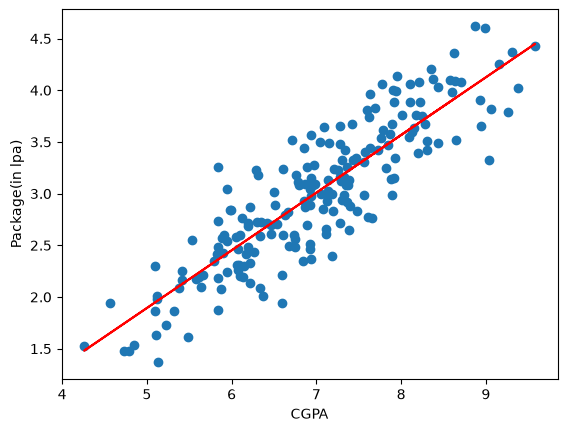

In [22]:
X = df.iloc[:,0:1]
y = df.iloc[:,-1]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

lr = LinearRegression()
lr.fit(X_train,y_train)

y_pred_train = lr.predict(X_train)

plt.scatter(df['cgpa'],df['package'])
plt.plot(X_train,y_pred_train,color='red')
plt.xlabel('CGPA')
plt.ylabel('Package(in lpa)')

In [23]:
m = lr.coef_
b = lr.intercept_

print("Slope " ,m)
print("Co-efficient " ,b)       

# y = mx + b
m * 6.89 + b

Slope  [0.55795197]
Co-efficient  -0.8961119222429144


array([2.94817717])

#### Simple Linear Regression code from Scratch

In [24]:
class MeraLR:
    
    def __init__(self):    #init cause yeh toh chalna hi chahiye
        self.m = None
        self.b = None
        
    def fit(self,X_train,y_train):
        num = 0
        den = 0
        
        for i in range(X_train.shape[0]):
#using formula to calculate m and b            
            num = num + ((X_train[i] - X_train.mean())*(y_train[i] - y_train.mean()))
            den = den + ((X_train[i] - X_train.mean())*(X_train[i] - X_train.mean()))
        
        self.m = num/den
        self.b = y_train.mean() - (self.m * X_train.mean())
        print("Slope " ,self.m)
        print("Co-efficient " ,self.b)       
    
    def predict(self,X_test):
        #This is will predict the value
        print(X_test)
        return self.m * X_test + self.b

In [25]:
#.values because we need numpy array
X = df.iloc[:,0].values
y = df.iloc[:,1].values

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

mlr = MeraLR()
mlr.fit(X_train,y_train)

print(X_train.shape)
print(X_train.shape[0])
print(mlr.predict(6.89))

Slope  0.5579519734250721
Co-efficient  -0.8961119222429152
(160,)
160
6.89
2.9481771746558314


## Regression Metric

In [26]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [27]:
df = pd.read_csv('DataSets/placement1.csv')
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


In [28]:
X = df.iloc[:,0:1]
y = df.iloc[:,-1]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

lr = LinearRegression()
lr.fit(X_train,y_train)

y_pred = lr.predict(X_test)

In [29]:
print("MAE",mean_absolute_error(y_test,y_pred))
print("MSE",mean_squared_error(y_test,y_pred))
print("RMSE",np.sqrt(mean_squared_error(y_test,y_pred)))
print("MSE",r2_score(y_test,y_pred))

print("Shape of X_test needed to calculate Adjusted R2",X_test.shape)

def adjusted_r2(y_true, y_pred, n_features):
    r2 = r2_score(y_true, y_pred)
    n = len(y_true)

    r2_adj = 1 - ((1 - r2) * (n - 1)) / (n - n_features - 1)

    return r2_adj
    
#r2 = r2_score(y_test,y_pred)
#r2_adj = 1 - ((1-r2)*(40-1)/(40-1-1))
print("Adjusted R2 Score", adjusted_r2(y_test,y_pred,1))

MAE 0.2884710931878175
MSE 0.12129235313495527
RMSE 0.34827051717731616
MSE 0.780730147510384
Shape of X_test needed to calculate Adjusted R2 (40, 1)
Adjusted R2 Score 0.7749598882343415


In [30]:
#Adding useless random feature
new_df1 = df.copy()
new_df1['random_feature'] = np.random.random(200)

new_df1 = new_df1[['cgpa','random_feature','package']]
new_df1.head()

,cgpa,random_feature,package
0,6.89,0.738040,3.26
1,5.12,0.566314,1.98
2,7.82,0.794379,3.25
3,7.42,0.927260,3.67
4,6.94,0.080862,3.57


Text(0, 0.5, 'Package(in lpa)')

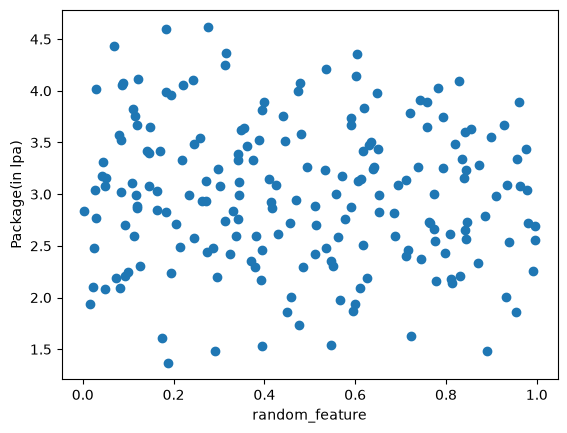

In [31]:
#Plotted to show it is random and no pattern or relation with package
plt.scatter(new_df1['random_feature'],new_df1['package'])
plt.xlabel('random_feature')
plt.ylabel('Package(in lpa)')

In [32]:
X = new_df1.iloc[:,0:2]
y = new_df1.iloc[:,-1]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

lr = LinearRegression()
lr.fit(X_train,y_train)

y_pred = lr.predict(X_test)

print("R2/MSE score",r2_score(y_test,y_pred))
print("Adjusted R2 Score", adjusted_r2(y_test,y_pred,2))
#adjusted went down but r2 has neglible change

R2/MSE score 0.7805479589773734
Adjusted R2 Score 0.7686856864896638


In [33]:
#Adding useful feature
new_df2 = df.copy()

new_df2['iq'] = new_df2['package'] + (np.random.randint(-12,12,200)/10)

new_df2 = new_df2[['cgpa','iq','package']]
new_df2.head()

,cgpa,iq,package
0,6.89,3.06,3.26
1,5.12,1.48,1.98
2,7.82,3.75,3.25
3,7.42,4.77,3.67
4,6.94,2.57,3.57


Text(0, 0.5, 'Package(in lpa)')

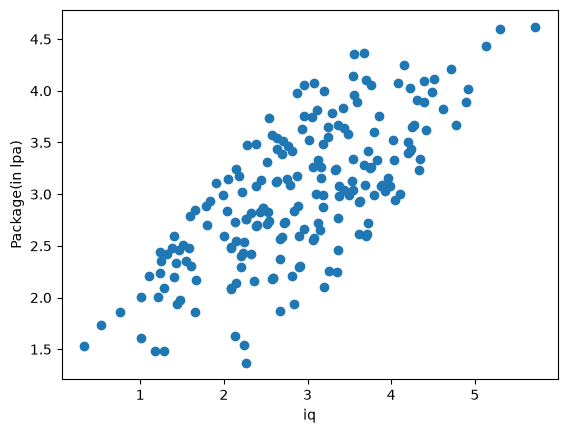

In [34]:
plt.scatter(new_df2['iq'],new_df2['package'])
plt.xlabel('iq')
plt.ylabel('Package(in lpa)')

In [35]:
X = new_df2.iloc[:,0:2]
y = new_df2.iloc[:,-1]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)

print("R2/MSE score",r2_score(y_test,y_pred))
print("Adjusted R2 Score", adjusted_r2(y_test,y_pred,2))
#Now both went up

R2/MSE score 0.8162314195091266
Adjusted R2 Score 0.8062979827258361


## Multiple Linear Regression

#### Multiple Linear Regression using library

In [36]:
from sklearn.datasets import make_regression
import pandas as pd
import numpy as np

import plotly.express as px
import plotly.graph_objects as go

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [37]:
#Making self dataset
X,y = make_regression(n_samples=100, n_features=2, n_informative=2, n_targets=1, noise=50)

df = pd.DataFrame({'feature1':X[:,0],'feature2':X[:,1],'target':y})

print(df.shape)
df.head()

(100, 3)


,feature1,feature2,target
0,-0.544575,-0.769962,-79.234840
1,-1.666055,0.698457,3.569059
2,0.857413,-0.273999,-6.023542
3,0.695209,-0.110915,-90.721886
4,-0.145294,-1.606575,-202.955825


In [38]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=3)

lr = LinearRegression()
lr.fit(X_train,y_train)

y_pred = lr.predict(X_test)

print("MAE",mean_absolute_error(y_test,y_pred))
print("MSE",mean_squared_error(y_test,y_pred))
print("R2 score",r2_score(y_test,y_pred))
print("Adjusted R2 Score", adjusted_r2(y_test,y_pred,2))
print("Value of m", lr.coef_)
print("Value of b ",lr.intercept_)
#two values of m because I have two features

MAE 48.00586315623666
MSE 3008.3187435550803
R2 score 0.623431119660163
Adjusted R2 Score 0.5791288984437115
Value of m [ 20.65790746 100.59550848]
Value of b  -1.7088857476668693


#### Multiple Linear Regression code from scratch

In [39]:
import numpy as np
from sklearn.datasets import load_diabetes

In [40]:
X,y = load_diabetes(return_X_y=True)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [41]:
class MeraLR:
    def __init__(self):
        self.coef_ = None
        self.intercept_ = None
        
    def fit(self,X_train,y_train):
        X_train = np.insert(X_train,0,1,axis=1)    #in our dataset we do not have 1 at front as it should be in the matrix 
        
        # calcuate the coeffs
        betas = np.linalg.inv(np.dot(X_train.T,X_train)).dot(X_train.T).dot(y_train)
        self.intercept_ = betas[0]
        self.coef_ = betas[1:]
    
    def predict(self,X_test):
        y_pred = np.dot(X_test,self.coef_) + self.intercept_
        return y_pred

In [42]:
print(X_train[0:8,:])
print(np.insert(X_train,0,1,axis=1)[0:8,:])
#You can see that a 1 is added in front of the values and is now fit for multiple linear regression

[[-0.00188202 -0.04464164 -0.06979687 -0.01255612 -0.00019301 -0.00914259
   0.07072993 -0.03949338 -0.06291688  0.04034337]
 [-0.00914709 -0.04464164  0.01103904 -0.05731319 -0.02496016 -0.04296262
   0.03023191 -0.03949338  0.01703607 -0.0052198 ]
 [ 0.02354575  0.05068012 -0.02021751 -0.03665608 -0.01395254 -0.01509241
   0.05968501 -0.03949338 -0.09643495 -0.01764613]
 [-0.02367725 -0.04464164  0.04552903  0.09072941 -0.01808039 -0.03544706
   0.07072993 -0.03949338 -0.03452178 -0.00936191]
 [-0.0382074  -0.04464164 -0.0547075  -0.07797029 -0.03321588 -0.08649026
   0.14068104 -0.0763945  -0.01919845 -0.0052198 ]
 [ 0.03807591  0.05068012 -0.00943939  0.00235142  0.00118295  0.03751653
  -0.05444576  0.05017634 -0.02595311  0.10661708]
 [-0.00914709  0.05068012  0.17055523  0.01498668  0.03007796  0.03375875
  -0.02131102  0.03430886  0.03365381  0.03205916]
 [ 0.06713621  0.05068012  0.02073935 -0.00567042  0.02044629  0.02624319
  -0.00290283 -0.00259226  0.0086406   0.00306441]]

In [43]:
mlr = MeraLR()
mlr.fit(X_train,y_train)

X_train.shape
np.insert(X_train,0,1,axis=1).shape

y_pred = mlr.predict(X_test)

print("MAE",mean_absolute_error(y_test,y_pred))
print("MSE",mean_squared_error(y_test,y_pred))
print("R2 score",r2_score(y_test,y_pred))
print("Adjusted R2 Score", adjusted_r2(y_test,y_pred,2))
print("Value of m", mlr.coef_)
print("Value of b ",mlr.intercept_)

MAE 45.21303419046905
MSE 3094.4566715660662
R2 score 0.4399338661568961
Adjusted R2 Score 0.42690907234659137
Value of m [  -9.15865318 -205.45432163  516.69374454  340.61999905 -895.5520019
  561.22067904  153.89310954  126.73139688  861.12700152   52.42112238]
Value of b  151.8833100525417


## Gradient Descent

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression

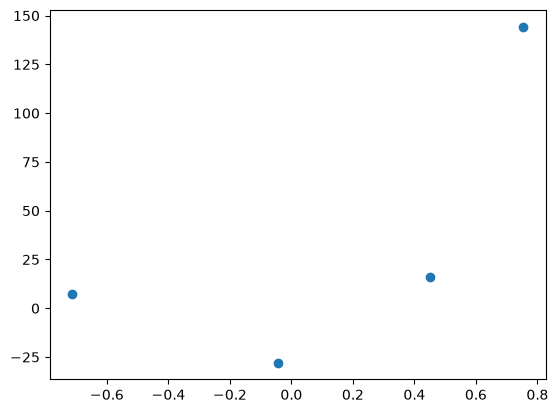

In [45]:
X,y = make_regression(n_samples=4, n_features=1, n_informative=1, n_targets=1,noise=80,random_state=13)
plt.scatter(X,y)

In [46]:
# Lets apply OLS
reg = LinearRegression()
reg.fit(X,y)
print("Value of m", lr.coef_)
print("Value of b ",lr.intercept_)

Value of m [ 20.65790746 100.59550848]
Value of b  -1.7088857476668693


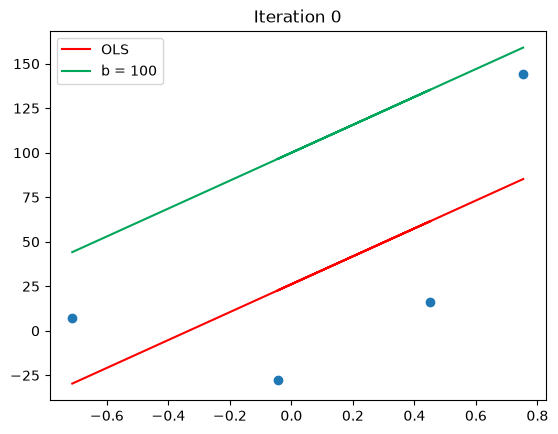

Loss Slope/Error Function for Iteration 1 590.7223659179078
New b after applying formula for Iteration 1 40.927763408209216


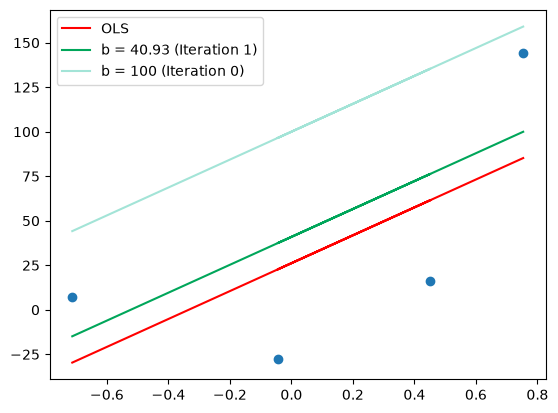

Loss Slope/Error Function for Iteration 2 118.14447318358157
New b after applying formula for Iteration 2 29.11331608985106


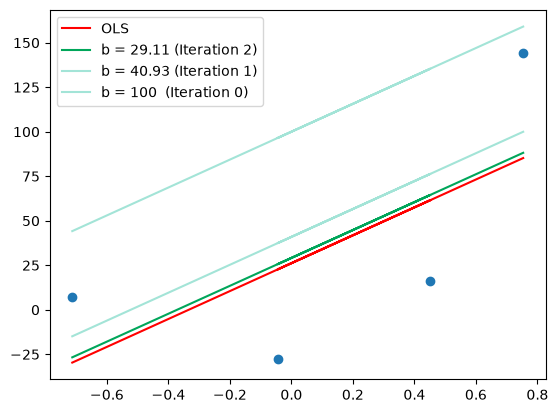

In [47]:
# Lets apply Gradient Descent assuming slope is constant m = 78.35
# and let's assume the starting value for intercept b = 0
m = 78.35
b = 100
y_pred = ((m * X) + b).reshape(4)

plt.scatter(X,y)
plt.title("Iteration 0")
plt.plot(X,reg.predict(X),color='red',label='OLS')
plt.plot(X,y_pred,color='#00a65a',label=f'b = {b}')
plt.legend()
plt.show()


#ITERATION 1
#loss slope is just Error function (E) summation of y-mx-b
#.ravel brings X datafrome form 2D to 1D
loss_slope = -2 * np.sum(y - m*X.ravel() - b)
print("Loss Slope/Error Function for Iteration 1",loss_slope)

# Lets take learning rate = 0.1
lr = 0.1

# Calculating the new intercept
b1 = b - loss_slope*lr
print("New b after applying formula for Iteration 1",b1)

y_pred1 = ((m * X) + b1).reshape(4)
plt.scatter(X,y)
plt.plot(X,reg.predict(X),color='red',label='OLS')
plt.plot(X,y_pred1,color='#00a65a',label='b = {:.2f} (Iteration 1)'.format(b1))
plt.plot(X,y_pred,color='#A3E4D7',label='b = 100 (Iteration 0)')
plt.legend()
plt.show()




#ITERATION 2
loss_slope = -2 * np.sum(y - m*X.ravel() - b1)
print("Loss Slope/Error Function for Iteration 2",loss_slope)

# Calculating the new intercept
b2 = b1 - loss_slope*lr
print("New b after applying formula for Iteration 2",b2)

y_pred2 = ((m * X) + b2).reshape(4)

plt.scatter(X,y)
plt.plot(X,reg.predict(X),color='red',label='OLS')
plt.plot(X,y_pred2,color='#00a65a',label='b = {:.2f} (Iteration 2)'.format(b2))
plt.plot(X,y_pred1,color='#A3E4D7',label='b = {:.2f} (Iteration 1)'.format(b1))
plt.plot(X,y_pred,color='#A3E4D7',label='b = 100  (Iteration 0)')
plt.legend()
plt.show()

#As you can see it is coming closer to OLS that mean it is also correct

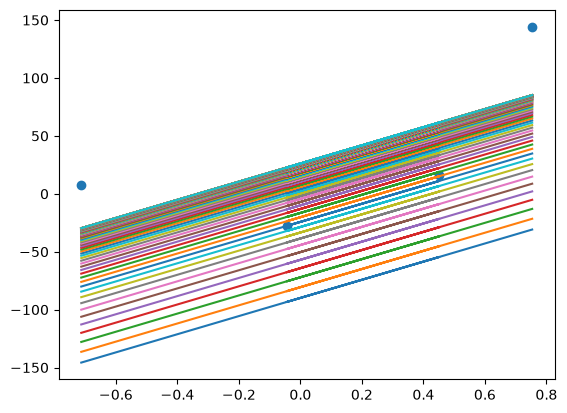

In [48]:
#This is how you can bring it in a loop
b = -100
m = 78.35
lr = 0.01

epochs = 100

for i in range(epochs):
  loss_slope = -2 * np.sum(y - m*X.ravel() - b)
  b = b - (lr * loss_slope)

  y_pred = m * X + b

  plt.plot(X,y_pred)

plt.scatter(X,y)

#### Below same thing is done just using own function and class that is code from scratch

In [49]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score


X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1,noise=20,random_state=13)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)


class MyGDRegressor:
    
    def __init__(self,learning_rate,epochs):
        self.m = 100
        self.b = -120
        self.lr = learning_rate
        self.epochs = epochs
        print("Number of iteration:", self.epochs)
        print("Value of m:", self.m)
        print("Value of b:", self.b)
        print("Value of learning rate:", self.lr)
        
    def fit(self,X,y):
        # calcualte the b using GD
        for i in range(self.epochs):
            loss_slope_b = -2 * np.sum(y - self.m*X.ravel() - self.b)
            loss_slope_m = -2 * np.sum((y - self.m*X.ravel() - self.b)*X.ravel())
            
            self.b = self.b - (self.lr * loss_slope_b)
            self.m = self.m - (self.lr * loss_slope_m)
        print("Final Value of m:" ,self.m)
        print("Final Value of b:" ,self.b)
        
    def predict(self,X):
        return self.m * X + self.b

mgd = MyGDRegressor(0.001,50)
mgd.fit(X_train,y_train)

y_pred = mgd.predict(X_test)
print("R2 Score is" ,r2_score(y_test,y_pred))
#We will get this R2 even with in built LR and OLS

Number of iteration: 50
Value of m: 100
Value of b: -120
Value of learning rate: 0.001
Final Value of m: 28.159367347119066
Final Value of b: -2.3004574196824854
R2 Score is 0.6343842836315579


## Types of Gradient Descent
#### Unitl now using Batch Gradient but only in 2D
#### Now it is in multidimensional format 

In [50]:
from sklearn.datasets import load_diabetes
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

In [51]:
#Code using built in function
X,y = load_diabetes(return_X_y=True)
print(X.shape)
print(y.shape)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

reg = LinearRegression()
reg.fit(X_train,y_train)

#Multiple values of m because it has multiple features
print("Values of m",reg.coef_)
print("Value of b",reg.intercept_)

y_pred = reg.predict(X_test)

print("R2/MSE Score",r2_score(y_test,y_pred))

(442, 10)
(442,)
Values of m [  -9.15865318 -205.45432163  516.69374454  340.61999905 -895.5520019
  561.22067904  153.89310954  126.73139688  861.12700152   52.42112238]
Value of b 151.88331005254167
R2/MSE Score 0.439933866156897


In [52]:
class MyGDRegressor:
    
    def __init__(self,learning_rate=0.01,epochs=100):
        
        self.coef_ = None
        self.intercept_ = None
        self.lr = learning_rate
        self.epochs = epochs
        
    def fit(self,X_train,y_train):
        # init your coefs
        self.intercept_ = 0
        self.coef_ = np.ones(X_train.shape[1])  #this tells us the number of coeff I need and initializes them to 1

#all of this looks scary but they basically just formulas
        for i in range(self.epochs):
            # update all the coef and the intercept
            #Vectorization
            y_hat = np.dot(X_train,self.coef_) + self.intercept_
            #print("Shape of y_hat",y_hat.shape)
            intercept_der = -2 * np.mean(y_train - y_hat)
            self.intercept_ = self.intercept_ - (self.lr * intercept_der)   
            coef_der = -2 * np.dot((y_train - y_hat),X_train)/X_train.shape[0]
            self.coef_ = self.coef_ - (self.lr * coef_der)
        
        print("Final Value of m:" ,self.intercept_)
        print("Final Value of b:" ,self.coef_)
    
    def predict(self,X_test):
        return np.dot(X_test,self.coef_) + self.intercept_


import time

mgdr = MyGDRegressor(epochs=1000,learning_rate=0.5)
start = time.time()
mgdr.fit(X_train,y_train)
print("The time taken is",time.time() - start)
y_pred = mgdr.predict(X_test)
print("R2/MSE Score",r2_score(y_test,y_pred))

Final Value of m: 152.01351687661833
Final Value of b: [  14.38990585 -173.7235727   491.54898524  323.91524824  -39.32648042
 -116.01061213 -194.04077415  103.38135565  451.63448787   97.57218278]
The time taken is 0.010768413543701172
R2/MSE Score 0.4534503034722803


### Stochastic Gradient Descent

In [53]:
from sklearn.datasets import load_diabetes

import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
import time

In [54]:
#This is just so that we can compare results of this linear regression with the one we are going to perform now
X,y = load_diabetes(return_X_y=True)

print(X.shape)
print(y.shape)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

reg = LinearRegression()
start = time.time()
reg.fit(X_train,y_train)
print("The time taken is",time.time() - start)

print("Values of m",reg.coef_)
print("Values of b",reg.intercept_)

y_pred = reg.predict(X_test)
print("R2/MSE Score",r2_score(y_test,y_pred))

(442, 10)
(442,)
The time taken is 0.0006933212280273438
Values of m [  -9.15865318 -205.45432163  516.69374454  340.61999905 -895.5520019
  561.22067904  153.89310954  126.73139688  861.12700152   52.42112238]
Values of b 151.88331005254167
R2/MSE Score 0.439933866156897


#### SDGRegressor Using Library

In [55]:
from sklearn.linear_model import SGDRegressor
reg = SGDRegressor(max_iter=100,learning_rate='constant',eta0=0.01)
start = time.time()
reg.fit(X_train,y_train)
print("The time taken is",time.time() - start)
y_pred = reg.predict(X_test)
print("R2/MSE Score",r2_score(y_test,y_pred))

The time taken is 0.0038094520568847656
R2/MSE Score 0.432812262543109


c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:1620: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


#### SDGRegressor Code from Scratch

In [56]:
class MySGDRegressor:
    
    def __init__(self,learning_rate=0.01,epochs=100):
        self.coef_ = None
        self.intercept_ = None
        self.lr = learning_rate
        self.epochs = epochs
        
    def fit(self,X_train,y_train):
        # init your coefs
        self.intercept_ = 0
        self.coef_ = np.ones(X_train.shape[1])
        
        for i in range(self.epochs):
            for j in range(X_train.shape[0]):   #here instead of putting entire dataset we are iterating the dataset completely  and randomly taking rows one by one and updating the coeff
                idx = np.random.randint(0,X_train.shape[0])
                
                y_hat = np.dot(X_train[idx],self.coef_) + self.intercept_
                
                intercept_der = -2 * (y_train[idx] - y_hat)
                self.intercept_ = self.intercept_ - (self.lr * intercept_der)
                
                coef_der = -2 * np.dot((y_train[idx] - y_hat),X_train[idx])
                self.coef_ = self.coef_ - (self.lr * coef_der)
        
        print("Values of m",reg.coef_)
        print("Values of b",reg.intercept_)
    
    def predict(self,X_test):
        return np.dot(X_test,self.coef_) + self.intercept_



msgd = MySGDRegressor(learning_rate=0.01,epochs=40)
start = time.time()
msgd.fit(X_train,y_train)
print("The time taken is",time.time() - start)

y_pred = msgd.predict(X_test)
print("R2/MSE Score",r2_score(y_test,y_pred))

Values of m [  55.7829053   -66.23493526  347.68942049  245.75142613   17.84344739
  -27.7577279  -172.41963144  129.12707809  316.30791503  128.48205659]
Values of b [153.6617304]
The time taken is 0.07663965225219727
R2/MSE Score 0.42122754922160033


In [57]:
# you will see that sgd is slower than batch gradient because you are comparing self function which uses python which is slow with in-built library which uses C/Fortran
#When comparing in-built GD and self made SGD we found GD is faster for same reason
# In-built Sdg is faster than self made SGD for obvious reasons
# Self made GD and SGD shows that SGD is faster
# Library Linear,GD,SGD shows that Linear>SGD because in diabetes dataset data is small so one big calculation is better than many small one. For highers dimension SGD will win and there is no in-built GD regression

### Mini Batch Gradient Descent

####  Mini Batch Gradient Descent using Library

In [58]:
from sklearn.linear_model import SGDRegressor
import random

sgd = SGDRegressor(learning_rate='constant',eta0=0.1)
batch_size = 35

for i in range(100): 
    idx = random.sample(range(X_train.shape[0]),batch_size)
    sgd.partial_fit(X_train[idx],y_train[idx])

print("Values of m",sgd.coef_)
print("Values of b",sgd.intercept_)

y_pred = sgd.predict(X_test)
print("R2/MSE Score",r2_score(y_test,y_pred))

Values of m [  58.50899916  -55.80883186  355.46902202  246.86029798    9.40793874
  -37.26525124 -184.55394881  132.73891542  317.30518787  133.05297327]
Values of b [158.91737859]
R2/MSE Score 0.4257054622828983


####  Mini Batch Gradient Descent Code from Scratch

In [59]:
from sklearn.datasets import load_diabetes

import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

In [60]:
X,y = load_diabetes(return_X_y=True)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

import random

class MyMBGDRegressor:
    def __init__(self,batch_size,learning_rate=0.01,epochs=100):
        
        self.coef_ = None
        self.intercept_ = None
        self.lr = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        
    def fit(self,X_train,y_train):
        # init your coefs
        self.intercept_ = 0
        self.coef_ = np.ones(X_train.shape[1])
        
        for i in range(self.epochs):
            
            for j in range(int(X_train.shape[0]/self.batch_size)):
                
                idx = random.sample(range(X_train.shape[0]),self.batch_size)
                
                y_hat = np.dot(X_train[idx],self.coef_) + self.intercept_
                #print("Shape of y_hat",y_hat.shape)
                intercept_der = -2 * np.mean(y_train[idx] - y_hat)
                self.intercept_ = self.intercept_ - (self.lr * intercept_der)

                coef_der = -2 * np.dot((y_train[idx] - y_hat),X_train[idx])
                self.coef_ = self.coef_ - (self.lr * coef_der)
        
        print("Values of m",reg.coef_)
        print("Values of b",reg.intercept_)
    
    def predict(self,X_test):
        return np.dot(X_test,self.coef_) + self.intercept_


mmbr = MyMBGDRegressor(batch_size=int(X_train.shape[0]/50),learning_rate=0.01,epochs=100)
mmbr.fit(X_train,y_train)
y_pred = mmbr.predict(X_test)
print("R2/MSE Score",r2_score(y_test,y_pred))

Values of m [  55.7829053   -66.23493526  347.68942049  245.75142613   17.84344739
  -27.7577279  -172.41963144  129.12707809  316.30791503  128.48205659]
Values of b [153.6617304]
R2/MSE Score 0.45122873666400165


## Polynomial Linear Regression

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,SGDRegressor
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline

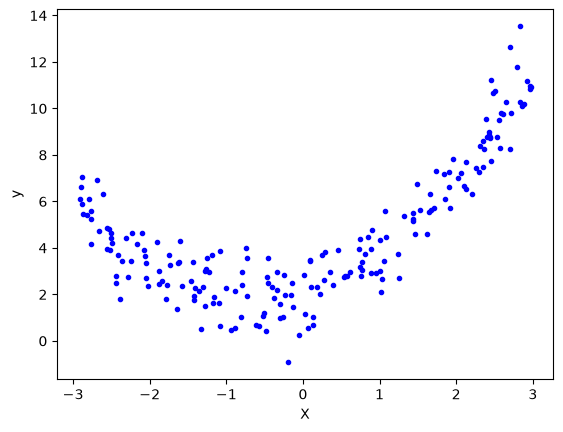

In [62]:
#creating random datset
X = 6 * np.random.rand(200, 1) - 3
y = 0.8 * X**2 + 0.9 * X + 2 + np.random.randn(200, 1)
# y = 0.8x^2 + 0.9x + 2

plt.plot(X, y,'b.')
plt.xlabel("X")
plt.ylabel("y")
plt.show()

In [63]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

# Applying Polynomial Linear Regression
poly = PolynomialFeatures(degree=2,include_bias=True)    #Bias false is no X^0 term

X_train_trans = poly.fit_transform(X_train)
X_test_trans = poly.transform(X_test)

print(X_train[0])
print(X_train_trans[0])

lr = LinearRegression()
lr.fit(X_train_trans,y_train)

y_pred = lr.predict(X_test_trans)
print("R2/MSE Score",r2_score(y_test,y_pred))

print("Value of m", lr.coef_)
print("Value of b", lr.intercept_)

[0.13062649]
[1.         0.13062649 0.01706328]
R2/MSE Score 0.9137421083510435
Value of m [[0.         0.96210323 0.76660561]]
Value of b [2.12251986]


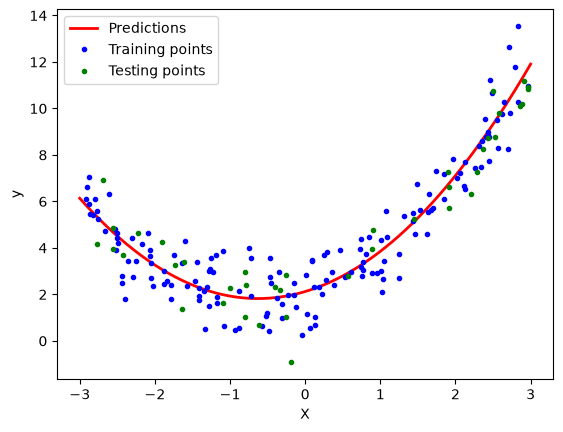

In [64]:
X_new=np.linspace(-3, 3, 200).reshape(200, 1)
X_new_poly = poly.transform(X_new)
y_new = lr.predict(X_new_poly)


plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")
plt.plot(X_train, y_train, "b.",label='Training points')
plt.plot(X_test, y_test, "g.",label='Testing points')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

In [65]:
# 3D polynomial regression where we solve multi feature problem
x = 7 * np.random.rand(100, 1) - 2.8
y = 7 * np.random.rand(100, 1) - 2.8

z = x**2 + y**2 + 0.2*x + 0.2*y + 0.1*x*y +2 + np.random.randn(100, 1)
# z = x^2 + y^2 + 0.2x + 0.2y + 0.1xy + 2

In [66]:
X_multi = np.hstack((x, y))
print(X_multi.shape)

poly = PolynomialFeatures(degree=2)
X_multi_trans = poly.fit_transform(X_multi)

print("Input", poly.n_features_in_)
print("Output", poly.n_output_features_)
print("Powers\n", poly.powers_)

lr = LinearRegression()
lr.fit(X_multi_trans,z)

#Prediction for x = 2 and y =3 (Same can be done for train test split)
X_test_point = np.array([[2, 3]])
X_test_point_trans = poly.transform(X_test_point)
y_pred = lr.predict(X_test_point_trans)
print("Value of m", lr.coef_)
print("Value of b", lr.intercept_)
print("Predicted z =", y_pred[0][0])

(100, 2)
Input 2
Output 6
Powers
 [[0 0]
 [1 0]
 [0 1]
 [2 0]
 [1 1]
 [0 2]]
Value of m [[0.         0.17934155 0.141488   0.98359728 0.10216371 1.01708295]]
Value of b [1.95253045]
Predicted z = 16.436795431660354


# Regularization

## Ridge Regression

#### Ridge Regression using library

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score,mean_squared_error

data=load_diabetes()

In [68]:
X=data.data
y=data.target

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=45)

R=Ridge(alpha=100)
R.fit(X_train,y_train)

print(R.coef_)
print(R.intercept_)

y_pred1=R.predict(X_test)

print("R2 score",r2_score(y_test,y_pred1))
print("RMSE",np.sqrt(mean_squared_error(y_test,y_pred1)))
#No much but slightly better and less complicated than linear regression

[ 2.50837637  0.49995432  7.60023083  5.95070245  2.22042419  1.72927261
 -5.00342409  5.10012612  7.16727454  5.12850186]
151.85033257177938
R2 score 0.025224686457473333
RMSE 69.35303270526724


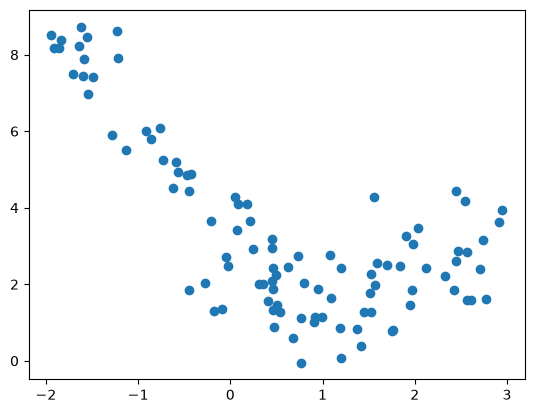

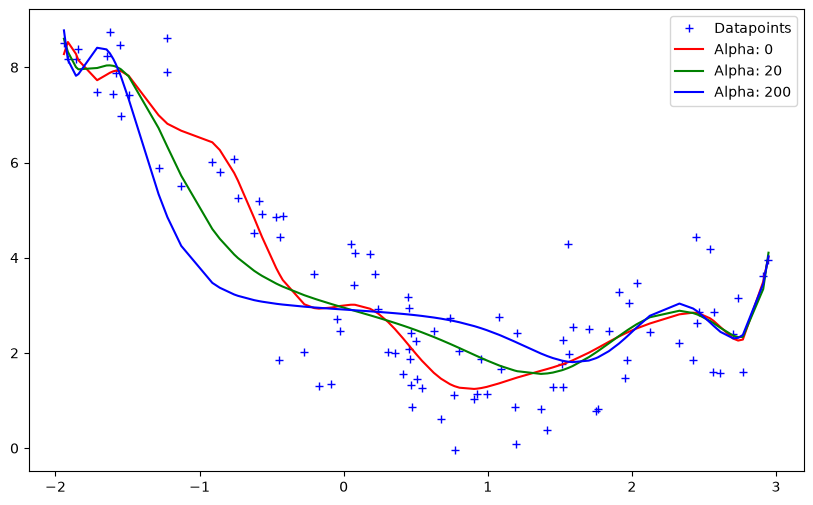

In [69]:
#This applies ridge regression on a dataset with values of lamba as 0 20 and 200 showing 20 is most optimal and high aplha gives underfitting while low alpha gives overfittin
m = 100
x1 = 5 * np.random.rand(m, 1) - 2
x2 = 0.7 * x1 ** 2 - 2 * x1 + 3 + np.random.randn(m, 1)

plt.scatter(x1, x2)
plt.show()

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

def get_preds_ridge(x1, x2, alpha):
    model = Pipeline([
        ('poly_feats', PolynomialFeatures(degree=16)),
        ('ridge', Ridge(alpha=alpha))
    ])
    model.fit(x1, x2)
    return model.predict(x1)

alphas = [0, 20, 200]
cs = ['r', 'g', 'b']

plt.figure(figsize=(10, 6))
plt.plot(x1, x2, 'b+', label='Datapoints')

for alpha, c in zip(alphas, cs):
    preds = get_preds_ridge(x1, x2, alpha)
    # Plot
    plt.plot(sorted(x1[:, 0]), preds[np.argsort(x1[:, 0])], c, label='Alpha: {}'.format(alpha))

plt.legend()
plt.show()

#### Ridge Regression code from Scratch

In [70]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.linear_model import LinearRegression

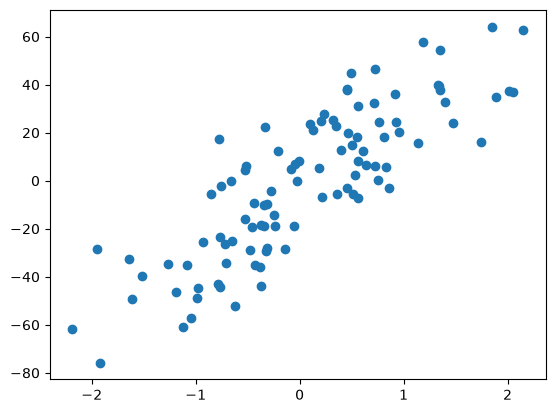

In [71]:
X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1,noise=20,random_state=13)

plt.scatter(X,y)

In [72]:
#Value we get from linear regression for comparison
lr = LinearRegression()
lr.fit(X,y)
print(lr.coef_)
print(lr.intercept_)

#Value we get from ridge regression library for different values of alpha for comparison with our code
rr = Ridge(alpha=10)
rr.fit(X,y)
print(rr.coef_)
print(rr.intercept_)

rr1 = Ridge(alpha=100)
rr1.fit(X,y)
print(rr1.coef_)
print(rr1.intercept_)

[27.82809103]
-2.29474455867698
[24.9546267]
-2.1269130035235735
[12.93442104]
-1.4248441496033308


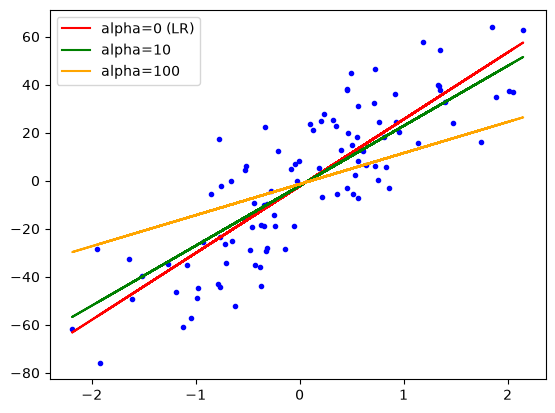

In [73]:
plt.plot(X,y,'b.')
plt.plot(X,lr.predict(X),color='red',label='alpha=0 (LR)')
plt.plot(X,rr.predict(X),color='green',label='alpha=10')
plt.plot(X,rr1.predict(X),color='orange',label='alpha=100')
plt.legend()

In [74]:
class MeraRidge:
    def __init__(self,alpha=0.1):
        self.alpha = alpha
        self.m = None
        self.b = None
        
    def fit(self,X_train,y_train):
        num = 0
        den = 0
        
        for i in range(X_train.shape[0]):
            num = num + (y_train[i] - y_train.mean())*(X_train[i] - X_train.mean())
            den = den + (X_train[i] - X_train.mean())*(X_train[i] - X_train.mean())
        
        self.m = num/(den + self.alpha)
        self.b = y_train.mean() - (self.m*X_train.mean())
        print("Value of m", self.m )
        print("Value of b", self.b)
    
    def predict(X_test):
        pass



mreg = MeraRidge(alpha=10)
mreg.fit(X,y)

Value of m [24.9546267]
Value of b [-2.126913]


#### Ridge Regression for n-dimensionsal data from Library

In [75]:
from sklearn.datasets import load_diabetes
from sklearn.metrics import r2_score
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge

In [76]:
X,y = load_diabetes(return_X_y=True)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=4)

reg = Ridge(alpha=0.1,solver='cholesky')  #solver is just a way of calculating and cholesky uses same formulas as ours
reg.fit(X_train,y_train)

y_pred = reg.predict(X_test)
r2_score(y_test,y_pred)

print("Value of m", reg.coef_)
print("Value of b", reg.intercept_)

print("R2 score",r2_score(y_test,y_pred1))

Value of m [  44.02063391 -241.69329987  452.98665299  332.04420177  -76.33686744
  -68.52143809 -164.98809083  149.96908118  431.61347417   58.51862681]
Value of b 150.89053425602808
R2 score -0.0033641149116332425


#### Ridge Regression for n-dimensionsal data from Scratch

In [77]:
class MeraRidge:
    
    def __init__(self,alpha=0.1):
        
        self.alpha = alpha
        self.coef_ = None
        self.intercept_ = None
        
    def fit(self,X_train,y_train):
        
        X_train = np.insert(X_train,0,1,axis=1)
        I = np.identity(X_train.shape[1])
        I[0][0] = 0    #In library they changing value of identity matrix first element to 0 form 1
        result = np.linalg.inv(np.dot(X_train.T,X_train) + self.alpha * I).dot(X_train.T).dot(y_train)
        self.intercept_ = result[0]
        self.coef_ = result[1:]
    
    def predict(self,X_test):
        return np.dot(X_test,self.coef_) + self.intercept_


mreg = MeraRidge()
mreg.fit(X_train,y_train)

y_pred = reg.predict(X_test)
print("Value of m", mreg.coef_)
print("Value of b", mreg.intercept_)
print("R2 score",r2_score(y_test,y_pred))

Value of m [  44.02063391 -241.69329987  452.98665299  332.04420177  -76.33686744
  -68.52143809 -164.98809083  149.96908118  431.61347417   58.51862681]
Value of b 150.8905342560281
R2 score 0.4693128853309805


### Ridge Regression using Gradient Descent

In [78]:
from sklearn.datasets import load_diabetes
from sklearn.metrics import r2_score
import numpy as np
from sklearn.model_selection import train_test_split

In [79]:
X,y = load_diabetes(return_X_y=True)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=4)

In [80]:
#Solving this using Stoichastic Gradient descent Redige Regression
from sklearn.linear_model import SGDRegressor
reg = SGDRegressor(penalty='l2',max_iter=500,eta0=0.1,learning_rate='constant',alpha=0.001)

reg.fit(X_train,y_train)

y_pred = reg.predict(X_test)
print("R2 score",r2_score(y_test,y_pred))
print("Value of m", reg.coef_)
print("Value of b", reg.intercept_)

R2 score 0.2169571923317788
Value of m [  53.51181368 -112.04107339  331.34976464  241.48055312   12.36269805
  -33.39238262 -166.33529242  143.51637488  299.75244954  114.54375821]
Value of b [120.38230313]


In [81]:
#Solving this using Ridge Regression class
from sklearn.linear_model import Ridge

reg = Ridge(alpha=0.001, max_iter=500,solver='sparse_cg')  
#sparse_cg ,sag, saga -> Gradient Descent
#auto, svd, cholesky -> OLS
reg.fit(X_train,y_train)

y_pred = reg.predict(X_test)
print("R2 score",r2_score(y_test,y_pred))
print("Value of m", reg.coef_)
print("Value of b", reg.intercept_)

R2 score 0.4625010162009602
Value of m [  34.52192661 -290.84083974  482.4018151   368.06786776 -852.44872998
  501.59160516  180.11115631  270.76334212  759.73534588   37.49135628]
Value of b 151.10198517848258


In [82]:
class MeraRidgeGD:
    
    def __init__(self,epochs,learning_rate,alpha):
        
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.alpha = alpha
        self.coef_ = None
        self.intercept_ = None
        
    def fit(self,X_train,y_train):
        
        self.coef_ = np.ones(X_train.shape[1])
        self.intercept_ = 0
        thetha = np.insert(self.coef_,0,self.intercept_)
        
        X_train = np.insert(X_train,0,1,axis=1)
        
        for i in range(self.epochs):
            thetha_der = np.dot(X_train.T,X_train).dot(thetha) - np.dot(X_train.T,y_train) + self.alpha*thetha
            thetha = thetha - self.learning_rate*thetha_der
        
        self.coef_ = thetha[1:]
        self.intercept_ = thetha[0]
    
    def predict(self,X_test):
        
        return np.dot(X_test,self.coef_) + self.intercept_


mreg = MeraRidgeGD(epochs=500,alpha=0.001,learning_rate=0.005)
mreg.fit(X_train,y_train)

y_pred = mreg.predict(X_test)
print("R2 score",r2_score(y_test,y_pred))
print("Value of m", mreg.coef_)
print("Value of b", mreg.intercept_)

# Best R2 using this ridge regression but ridge regressioon class should also have given good result

R2 score 0.4738018280260914
Value of m [  46.65050914 -221.3750037   452.12080647  325.54248128  -29.09464178
  -96.47517735 -190.90017011  146.32900372  400.80267299   95.09048094]
Value of b 150.86975316713472


## Elastic Net Regression

In [83]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression,Ridge,Lasso,ElasticNet
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

In [84]:
X,y = load_diabetes(return_X_y=True)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [85]:
# Linear Regression
reg = LinearRegression()
reg.fit(X_train,y_train)
y_pred = reg.predict(X_test)
print("R2 score using LR",r2_score(y_test,y_pred))



# ElasticNet
reg = ElasticNet(alpha=0.005,l1_ratio=0.9)
reg.fit(X_train,y_train)
y_pred = reg.predict(X_test)
print("R2 score using ElasticNet",r2_score(y_test,y_pred))

#or you can use elasticnet using sgd regressor as it have in build attributes which allow you to use l1,l2 and elastic net so you can check the sk learn library on how to use it

R2 score using LR 0.439933866156897
R2 score using ElasticNet 0.4531474541554823


## LOGISTICS REGRESSION

### Perceptron Trick With and Without Sigmoid

In [86]:
import numpy as np
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt

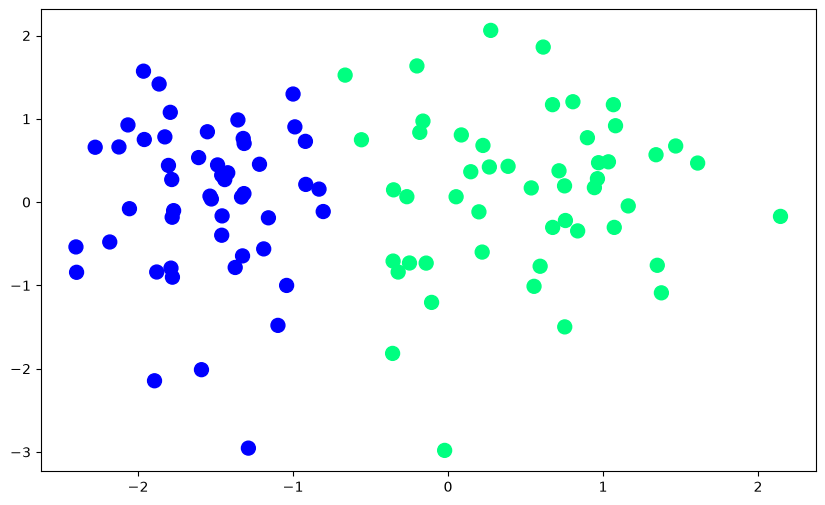

In [87]:
X, y = make_classification(n_samples=100, n_features=2, n_informative=1,n_redundant=0, n_classes=2, n_clusters_per_class=1, random_state=41,hypercube=False,class_sep=10)

plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

### Without Sigmoid

In [88]:
#This is still not best the in-built logistic regression give better results
def perceptronwithoutsigmoid(X,y):
    
    X = np.insert(X,0,1,axis=1)   #ek naya column bana diya with all 1
    weights = np.ones(X.shape[1])
    lr = 0.1
    
    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weights))
        weights = weights + lr*(y[j]-y_hat)*X[j]
    
    return weights[0],weights[1:]

def step(z):
    return 1 if z>0 else 0

pintercept_,pcoef_ = perceptronwithoutsigmoid(X,y)
print("Value of m with preceptron trick", pcoef_)
print("Value of b with preceptron trick", pintercept_)

m1 = -(pcoef_[0]/pcoef_[1])
b1 = -(pintercept_/pcoef_[1])

x_input1 = np.linspace(-3,3,100)
y_input1 = m1*x_input1 + b1

Value of m with preceptron trick [1.33723375 0.19877737]
Value of b with preceptron trick 0.9


### With Sigmoid

In [89]:
#This is better but still not best
def perceptronwithsigmoid(X,y):
    
    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1
    
    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = sigmoid(np.dot(X[j],weights))
        weights = weights + lr*(y[j]-y_hat)*X[j]
        
    return weights[0],weights[1:]

def sigmoid(z):
    return 1/(1 + np.exp(-z))


psintercept_,pscoef_ = perceptronwithsigmoid(X,y)
print("Value of m with preceptron trick with sigmoid", pscoef_)
print("Value of b with preceptron trick with sigmoid", psintercept_)

m2 = -(pscoef_[0]/pscoef_[1])
b2 = -(psintercept_/pscoef_[1])

x_input2 = np.linspace(-3,3,100)
y_input2 = m2*x_input2 + b2

Value of m with preceptron trick with sigmoid [4.41437996 0.07812146]
Value of b with preceptron trick with sigmoid 2.63617237056949


### Using Gradient Descent

In [90]:
def GradientDescent(X,y):
    
    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.5
    
    for i in range(5000):
        y_hat = sigmoid(np.dot(X,weights))
        weights = weights + lr*(np.dot((y-y_hat),X)/X.shape[0])
        
    return weights[1:],weights[0]

def sigmoid(z):
    return 1/(1 + np.exp(-z))


gdcoef_,gdintercept_ = GradientDescent(X,y)
print("Value of m with Gradient Descent", gdcoef_)
print("Value of b with Gradient Descent", gdintercept_)

m3 = -(gdcoef_[0]/gdcoef_[1])
b3 = -(gdintercept_/gdcoef_[1])

x_input3 = np.linspace(-3,3,100)
y_input3 = m3*x_input3 + b3

Value of m with Gradient Descent [11.9130685   0.80686829]
Value of b with Gradient Descent 7.890931726180508


### Using in-built

In [91]:
from sklearn.linear_model import LogisticRegression
lor = LogisticRegression(penalty=None,solver='sag')
lor.fit(X,y)

print("Value of m with library", lor.coef_)
print("Value of b with library", lor.intercept_)

m4 = -(lor.coef_[0][0]/lor.coef_[0][1])
b4 = -(lor.intercept_/lor.coef_[0][1])

x_input4 = np.linspace(-3,3,100)
y_input4 = m4*x_input4 + b4

Value of m with library [[13.63314939  1.00465056]]
Value of b with library [9.03595765]


c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


(-3.0, 2.0)

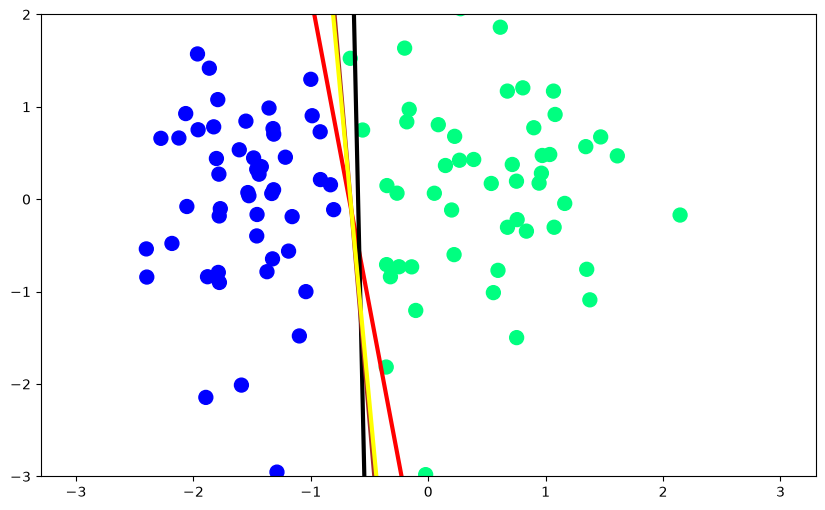

In [92]:
plt.figure(figsize=(10,6))
plt.plot(x_input1,y_input1,color='red',linewidth=3)
plt.plot(x_input2,y_input2,color='black',linewidth=3)
plt.plot(x_input3,y_input3,color='brown',linewidth=3)
plt.plot(x_input4,y_input4,color='yellow',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

In [93]:
# As you can see heirarchy is library > gd > sigmoid preceptron > simple perceptron

## Classification Metrics

In [94]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier


In [95]:
df = pd.read_csv('DataSets/heart_disease.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [96]:
X_train,X_test,y_train,y_test = train_test_split(df.iloc[:,0:-1],df.iloc[:,-1],test_size=0.2,random_state=2)

clf1 = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf1.fit(X_train,y_train)
clf2.fit(X_train,y_train)

y_pred1 = clf1.predict(X_test)
y_pred2 = clf2.predict(X_test)

c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [97]:
from sklearn.metrics import accuracy_score,confusion_matrix
print("Accuracy of Logistic Regression",accuracy_score(y_test,y_pred1))
print("Accuracy of Decision Trees",accuracy_score(y_test,y_pred2))


from sklearn.metrics import recall_score,precision_score,f1_score
print("For Logistic regression Model")
print("-"*50)
cdf = pd.DataFrame(confusion_matrix(y_test,y_pred1),columns=list(range(0,2)))
print(cdf)
print("-"*50)
print("Precision - ",precision_score(y_test,y_pred1))
print("Recall - ",recall_score(y_test,y_pred1))
print("F1 score - ",f1_score(y_test,y_pred1))


print("For DT Model")
print("-"*50)
cdf = pd.DataFrame(confusion_matrix(y_test,y_pred2),columns=list(range(0,2)))
print(cdf)
print("-"*50)
print("Precision - ",precision_score(y_test,y_pred2))
print("Recall - ",recall_score(y_test,y_pred2))
print("F1 score - ",f1_score(y_test,y_pred2))

#precision_score(y_test,y_pred1,average=None)
#these scores can also have different average choices like None, Weighted and more

Accuracy of Logistic Regression 0.8390243902439024
Accuracy of Decision Trees 0.9804878048780488
For Logistic regression Model
--------------------------------------------------
    0   1
0  80  25
1   8  92
--------------------------------------------------
Precision -  0.7863247863247863
Recall -  0.92
F1 score -  0.847926267281106
For DT Model
--------------------------------------------------
     0    1
0  101    4
1    0  100
--------------------------------------------------
Precision -  0.9615384615384616
Recall -  1.0
F1 score -  0.9803921568627451


In [98]:
confusion_matrix(y_test,y_pred1)

print("Logistic Regression Confusion Matrix")
print(pd.DataFrame(confusion_matrix(y_test,y_pred1),columns=list(range(0,2))))

print("\n")
      
print("Decision Tree Confusion Matrix")
print(pd.DataFrame(confusion_matrix(y_test,y_pred2),columns=list(range(0,2))))

Logistic Regression Confusion Matrix
    0   1
0  80  25
1   8  92


Decision Tree Confusion Matrix
     0    1
0  101    4
1    0  100


## ROC AUC Curve

In [99]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import plotly.graph_objects as go
from sklearn.svm import SVC
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import StandardScaler

In [100]:
data = pd.read_csv('DataSets/india_diabetes.csv')
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [101]:
# Split data
X = data.drop('Outcome', axis=1)
y = data['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2
)

# Scale data for SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

lr_scores = lr.predict_proba(X_test)[:,1]

# SVM
svm = SVC(probability=True)
svm.fit(X_train_scaled, y_train)

svm_scores = svm.predict_proba(X_test_scaled)[:,1]

# ROC Data
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_scores)
svm_fpr, svm_tpr, _ = roc_curve(y_test, svm_scores)

# AUC Scores
lr_auc = roc_auc_score(y_test, lr_scores)
svm_auc = roc_auc_score(y_test, svm_scores)

# Plot
fig = go.Figure()

fig.add_trace(go.Scatter(x=lr_fpr, y=lr_tpr, mode='lines', name=f'Logistic Regression (AUC={lr_auc:.2f})'))
fig.add_trace(go.Scatter(x=svm_fpr, y=svm_tpr, mode='lines', name=f'SVM (AUC={svm_auc:.2f})'))
fig.add_trace(go.Scatter(x=[0,1], y=[0,1], mode='lines', line=dict(dash='dash'), name='Random'))

fig.update_layout(title='ROC Curve', xaxis_title='False Positive Rate', yaxis_title='True Positive Rate', width=800, height=800)

fig.show()

c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


### SoftMax Regression

In [102]:
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [103]:
df = sns.load_dataset('iris')
df.sample()

URLError: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1032)>

In [104]:
#Applied One Hot Encoding
encoder = LabelEncoder()
df['species'] = encoder.fit_transform(df['species'])

df = df[['sepal_length','petal_length','species']]

X = df.iloc[:,0:2]
y = df.iloc[:,-1]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

#New library automatically chooses the multinomial class
#clf = LogisticRegression(multi_class='multinomial')
clf = LogisticRegression()
clf.fit(X_train,y_train)

y_pred = clf.predict(X_test)
print("Accuracy Score of Softmax Regression",accuracy_score(y_test,y_pred))

print("Confusion Matrix")
print(pd.DataFrame(confusion_matrix(y_test,y_pred)))

KeyError: 'species'

In [105]:
#prediction for a single value
#It tell the probability of the output classification and one with highest value is given
#all sum to 1
query = pd.DataFrame([[3.4, 2.7]], columns=['sepal_length', 'petal_length'])
clf.predict_proba(query)

NameError: name 'clf' is not defined

### Polynomial Logistics Regression

In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import PolynomialFeatures

In [108]:
X, y = make_moons(n_samples=200, noise=0.1, random_state=42)

df = pd.DataFrame(X, columns=['X', 'Y'])
df['class'] = y

df.to_csv('DataSets/ushape.csv', index=False)
df.head()

,X,Y,class
0,-1.049426,0.084443,0
1,0.922818,0.457489,0
2,0.656787,0.699597,0
3,1.188940,-0.386528,1
4,0.289265,-0.137745,1


In [109]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values


def plot_decision_boundary(X,y,degree=1):
    
    poly = PolynomialFeatures(degree=degree)
    X_trf = poly.fit_transform(X)
    
    clf = LogisticRegression()
    clf.fit(X_trf,y)
    
    accuracy = np.mean(cross_val_score(clf,X_trf,y,scoring='accuracy',cv=10))
    
    a=np.arange(start=X[:,0].min()-1, stop=X[:,0].max()+1, step=0.01)
    b=np.arange(start=X[:,1].min()-1, stop=X[:,1].max()+1, step=0.01)


    XX,YY=np.meshgrid(a,b)
    
    input_array=np.array([XX.ravel(),YY.ravel()]).T

    labels=clf.predict(poly.transform(input_array))
    
    plt.contourf(XX,YY,labels.reshape(XX.shape),alpha=0.5)
    plt.scatter(X[:,0],X[:,1], c=y)
    plt.title('Degree = {}, accuracy is {}'.format(degree,np.round(accuracy,4)))

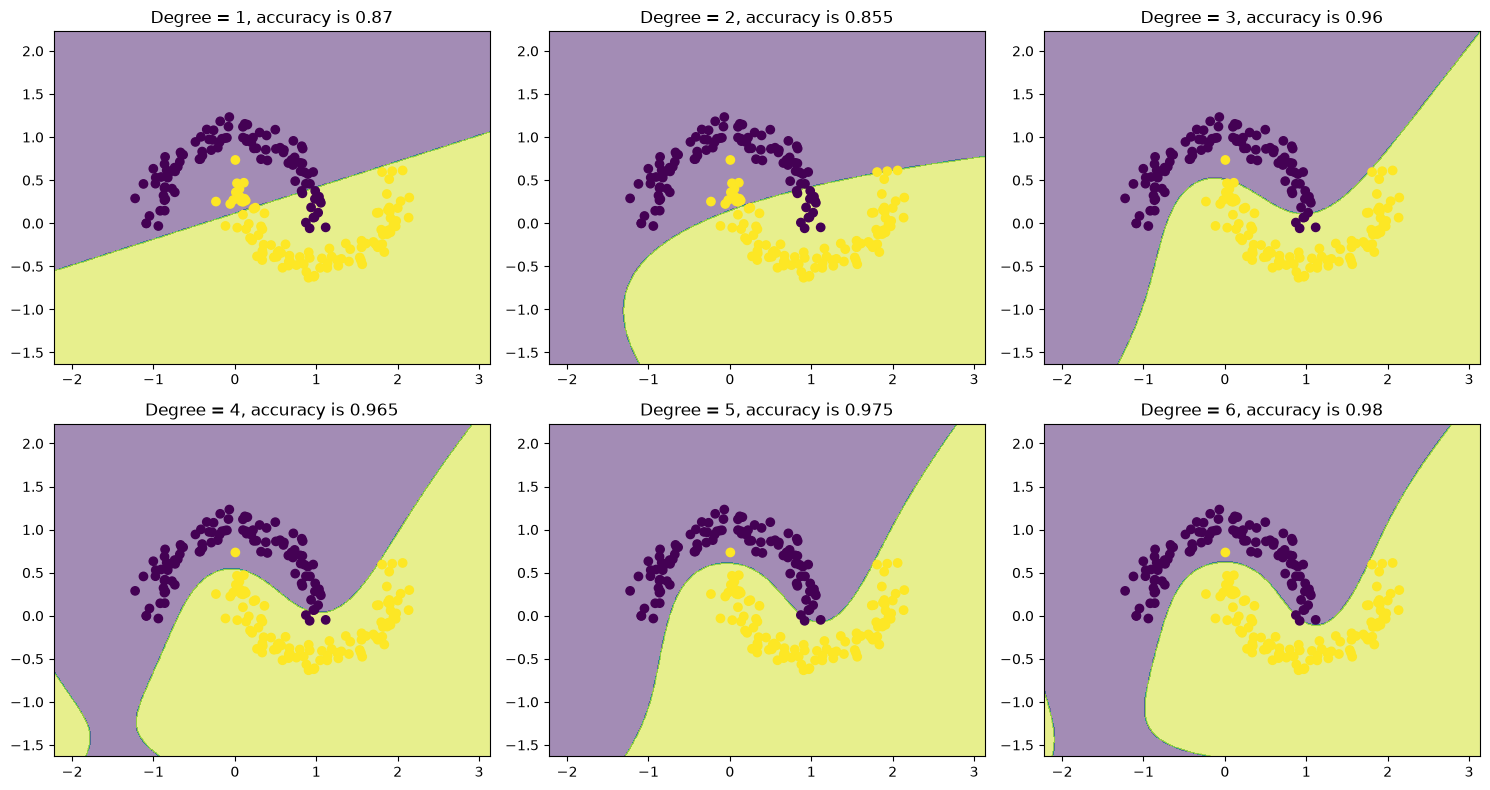

In [110]:
plt.figure(figsize=(15,8))

for i in range(1,7):
    plt.subplot(2,3,i)
    plot_decision_boundary(X, y, degree=i)

plt.tight_layout()
plt.show()

## Naive Bayes

In [111]:
import numpy as np
import pandas as pd

In [112]:
data = pd.read_csv('DataSets/play_tennis.csv')
data.drop(columns=['day'],inplace=True)
data.head()

,outlook,temp,humidity,wind,play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes


In [113]:
#Lookup table ie calculating probabilities which are going to be used in the follow up question

#match played or not
print(data['play'].value_counts())

play
Yes    9
No     5
Name: count, dtype: int64


In [114]:
py = 9/14
pn = 5/14

In [115]:
#outlook
print(pd.crosstab(data['outlook'], data['play']))

play      No  Yes
outlook          
Overcast   0    4
Rain       2    3
Sunny      3    2


In [116]:
pon = 0
prn = 2/5
psn = 3/5

poy = 4/9
pry = 3/9
psy = 2/9

In [117]:
#temp
print(pd.crosstab(data['temp'], data['play']))

play  No  Yes
temp         
Cool   1    3
Hot    2    2
Mild   2    4


In [118]:
pcn = 1/5
phn = 2/5
pmn = 2/5

pcy = 3/9
phy = 2/9
pmy = 4/9

In [119]:
#humidity
print(pd.crosstab(data['humidity'], data['play']))

play      No  Yes
humidity         
High       4    3
Normal     1    6


In [120]:
phighn = 4/5
pnormaln = 1/5

phighy = 3/9
pnormaly = 6/9

In [121]:
#wind
print(pd.crosstab(data['wind'], data['play']))

play    No  Yes
wind           
Strong   3    3
Weak     2    6


In [122]:
PStrongNo = 3/5
PWeakNo   = 2/5

PStrongYes = 3/9
PWeakYes   = 6/9

## K-Nearest-Neighbours

In [123]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier

In [124]:
df = pd.read_csv('DataSets/breastcancer.csv')
df.drop(columns=['id','Unnamed: 32'],inplace=True)
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [125]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:,1:], df.iloc[:,0],test_size=0.2, random_state=2)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train,y_train)

y_pred = knn.predict(X_test)
print("Accuracy score",accuracy_score(y_test,y_pred))

Accuracy score 0.9912280701754386


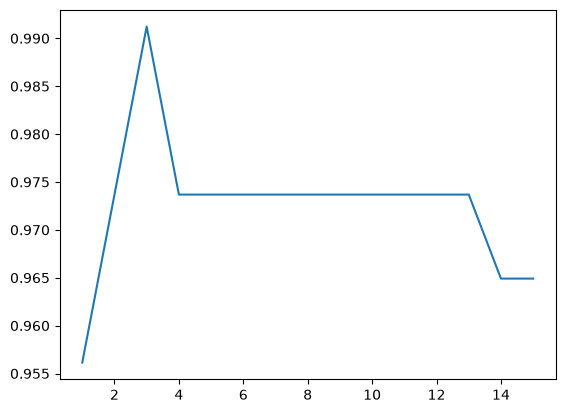

In [126]:
#makibng a function to try different values of k and find accuracy and take best k
scores = []

for i in range(1,16):
    knn = KNeighborsClassifier(n_neighbors=i)
    
    knn.fit(X_train,y_train)
    y_pred = knn.predict(X_test)
    scores.append(accuracy_score(y_test, y_pred))

plt.plot(range(1,16),scores)

#best acc for k =3

## SVM

In [127]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.axes._axes import _log as matplotlib_axes_logger
from mpl_toolkits import mplot3d
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from matplotlib.colors import ListedColormap
from sklearn.metrics import accuracy_score

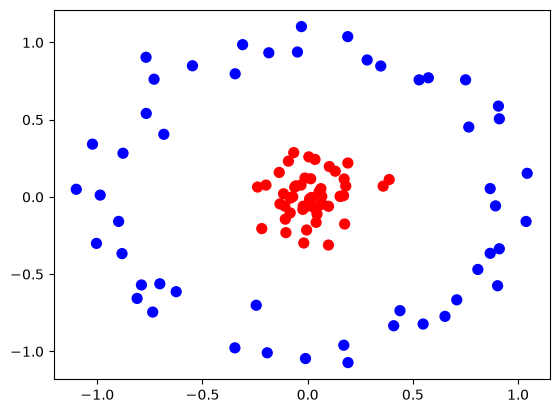

In [128]:
from sklearn.datasets import make_circles

X, y = make_circles(100, factor=.1, noise=.1)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='bwr')

In [129]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20)

classifier = SVC(kernel='linear')
classifier.fit(X_train, y_train.ravel())
y_pred = classifier.predict(X_test)
print("Accuracy score",accuracy_score(y_test,y_pred))

Accuracy score 0.4


In [130]:
def plot_3d_plot(X, y):
    r = np.exp(-(X ** 2).sum(1))
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=100, cmap='bwr')

    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.set_zlabel('y')

    return ax

<Axes3D: xlabel='x1', ylabel='x2', zlabel='y'>

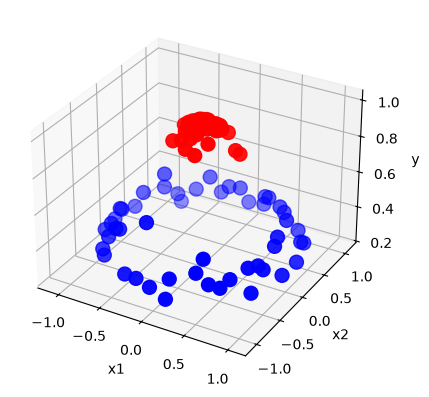

In [131]:
plot_3d_plot(X,y)

In [132]:
# Now it can be classified into different categories with a plane